# From an EO poster to defensible discovery

**Terrain & Earth observation · 25–35 minutes · original browser companion**

**Learning question:** How can a useful sensor capability become a bounded dataset-discovery proposal without pretending that a mission name, an API or a workflow is interchangeable?

The [EO Satellite Guide](https://jltobias.github.io/JupyterLite-EO-Satellite-Guide/explorer/) invites learners to explore sensing families, platforms, sensors and products before selecting data. This chapter explains that discovery experience and proposes a careful connection with [STAC Browser](../stac-browser/index.ipynb) and [ESA EarthCODE](https://earthcode.esa.int/). Its executable companion uses **five fictional candidate products across four fictional missions**. It is synthetic teaching metadata, with no actual acquisitions, measurements or health effects. The calculation uses only Python's standard library and local IPython SVG display: no installs, credentials, files, network requests or model calls.

The source poster is linked, not reproduced. The original route figure below exposes which relationships remain unknown. [Visual provenance](../../visual-provenance.ipynb).


## Predict before running

For surface reflectance at processing level L2A, predict which row can become a **printed draft**, which rows are incompatible, which lacks a verified collection, and which must be browsed as a static catalog. Retired describes the mission, not whether an archived product is usable. Optical SR and TOA share one mission but represent different properties/levels.

Run in order with **Shift+Enter**, or **Run → Run All Cells**. The first cell defines local SVG helpers, the second defines validation/routing, and the third contains the editable fixture and figure. A property/level mismatch is classified first; then a missing mapping; then static browsing; then unconfirmed API Item Search; then a draft. Explicit `None` is not silently discarded.

On a small screen, use the normal-sized printed evidence below the activity for every row and proposal field. In the Book, use your browser's **Open Image in New Tab** command on the wide figure to inspect it at full size.

The taught query deliberately accepts a finite, noncrossing, nondegenerate WGS84 rectangle, UTC start/end in order, and an integer page size 1–100. Invalid edits raise `ValueError` before any draft. These are exercise/source-app restrictions, not universal STAC rules: STAC permits degenerate bbox and provider limits differ. A provider can also impose different area/date limits.


In [1]:
from IPython.display import SVG, display
from html import escape

def svg(body, title, description, width=760, height=330):
    label = escape(title, quote=True)
    display(SVG(f'<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 {width} {height}" role="img" aria-label="{label}"><title>{escape(title)}</title><desc>{escape(description)}</desc><rect width="100%" height="100%" fill="#f5f5ef" rx="12"/>{body}</svg>'))

def bars(values, title, unit):
    print(title + ' | ' + unit + ':', {k:round(v,3) for k,v in values.items()})
    n = len(values)
    height = max(250, 82 + n*36)
    maximum = max(max(values.values()), 1)
    body = f'<text x="22" y="30" font-family="sans-serif" font-size="18" fill="#123c45">{escape(title)}</text>'
    for i,(key,value) in enumerate(values.items()):
        y=58+i*36
        body += f'<text x="22" y="{y+17}" font-family="sans-serif" font-size="13">{escape(str(key))}</text><rect x="205" y="{y}" width="{max(0,value)/maximum*440:.2f}" height="23" rx="3" fill="#16756b"/><text x="{213+max(0,value)/maximum*440:.2f}" y="{y+17}" font-family="sans-serif" font-size="13">{value:.2f}</text>'
    body += f'<text x="205" y="{height-15}" font-family="sans-serif" font-size="12">zero baseline · {escape(unit)}</text>'
    svg(body, title, 'Values are printed as a text alternative; consult the chart title for data status.', height=height)

def grid(values, columns, title):
    print(title + ':', [round(v,3) for v in values])
    maximum = max(max(values),1)
    size = 54
    body = f'<text x="22" y="30" font-family="sans-serif" font-size="18">{escape(title)}</text>'
    for i,v in enumerate(values):
        x=25+(i%columns)*size; y=52+(i//columns)*size
        light=92-50*v/maximum
        body += f'<rect x="{x}" y="{y}" width="50" height="50" fill="hsl(169,45%,{light:.1f}%)" stroke="#123c45"/><text x="{x+25}" y="{y+29}" text-anchor="middle" font-family="sans-serif" font-size="14" fill="#061c21">{v:.1f}</text>'
    svg(body,title,'Synthetic grid with values printed in each cell; no actual boundaries.',height=max(220,70+((len(values)+columns-1)//columns)*size))

def lines(series, title, xunit, yunit):
    print(title + ':', {k:[round(v,3) for v in vs] for k,vs in series.items()})
    maximum=max(max(vs) for vs in series.values()) or 1
    body=f'<text x="22" y="30" font-family="sans-serif" font-size="18">{escape(title)}</text><path d="M55 55V265H710" fill="none" stroke="#123c45"/>'
    for j,(name,vs) in enumerate(series.items()):
        color=['#16756b','#a34712','#41449c'][j%3]
        pts=' '.join(f'{55+i*650/max(1,len(vs)-1):.1f},{265-v*200/maximum:.1f}' for i,v in enumerate(vs))
        body+=f'<polyline points="{pts}" fill="none" stroke="{color}" stroke-width="3"/><text x="{60+j*220}" y="310" font-family="sans-serif" font-size="13" fill="{color}">{escape(name)}</text>'
    body+=f'<text x="55" y="288" font-family="sans-serif" font-size="12">{escape(xunit)} → · {escape(yunit)} ↑ · y starts at zero</text>'
    svg(body,title,'Synthetic series; printed values are the text alternative.')


In [2]:
import json
from datetime import datetime
from math import isfinite

ROUTES = ('draft', 'incompatible', 'unmapped', 'browse-static', 'check-api')

def validate_query(bbox, start, end, limit):
    """Exercise limits: finite noncrossing WGS84 rectangle, UTC dates, 1..100."""
    if not isinstance(bbox, (list, tuple)) or len(bbox) != 4:
        raise ValueError('bbox needs four WGS84 numbers: west, south, east, north')
    try:
        invalid_number = any(isinstance(v, bool) or not isinstance(v, (int, float)) or not isfinite(v) for v in bbox)
    except OverflowError as exc:
        raise ValueError('bbox coordinates must be finite WGS84 numbers') from exc
    if invalid_number:
        raise ValueError('bbox coordinates must be finite numbers')
    west, south, east, north = bbox
    if not (-180 <= west < east <= 180 and -90 <= south < north <= 90):
        raise ValueError('Use a noncrossing, nondegenerate WGS84 rectangle')
    try:
        first = datetime.strptime(start, '%Y-%m-%dT%H:%M:%SZ')
        last = datetime.strptime(end, '%Y-%m-%dT%H:%M:%SZ')
    except (ValueError, TypeError) as exc:
        raise ValueError('Use valid UTC dates in YYYY-MM-DDTHH:MM:SSZ form') from exc
    if first.strftime('%Y-%m-%dT%H:%M:%SZ') != start or last.strftime('%Y-%m-%dT%H:%M:%SZ') != end:
        raise ValueError('Use canonical UTC dates in YYYY-MM-DDTHH:MM:SSZ form')
    if first > last:
        raise ValueError('start must be before or equal to end')
    if isinstance(limit, bool) or not isinstance(limit, int) or not 1 <= limit <= 100:
        raise ValueError('limit must be an integer from 1 through 100')
    return {'bbox': list(bbox), 'datetime': start + '/' + end, 'limit': limit}

def route_candidate(row, target_property, target_processing):
    if (row['property'], row['processing']) != (target_property, target_processing):
        return 'incompatible'
    if row['collection'] is None:
        return 'unmapped'
    if row['kind'] == 'static':
        return 'browse-static'
    if row['kind'] != 'api' or row['item_search'] is not True:
        return 'check-api'
    return 'draft'

def discovery_plan(candidates, target_property, target_processing, bbox, start, end, limit):
    query = validate_query(bbox, start, end, limit)  # invalid edits stop before any draft
    routed = [dict(row, route=route_candidate(row, target_property, target_processing)) for row in candidates]
    counts = {route: sum(row['route'] == route for row in routed) for route in ROUTES}
    proposals = [{'simulation': True, 'status': 'proposal-only',
                  'intent': {'candidate': row['id'], 'mission': row['mission'],
                             'property': target_property, 'processing': target_processing},
                  'search': dict(query, collections=[row['collection']])}
                 for row in routed if row['route'] == 'draft']
    return routed, counts, proposals


Fictional candidates: 5 | fictional missions: 4
Target: surface_reflectance / L2A
Routes: {'draft': 1, 'incompatible': 2, 'unmapped': 1, 'browse-static': 1, 'check-api': 0}
optical-sr | demo-optical | active | collection: demo-optical-sr | property: surface_reflectance | processing: L2A | route: draft
optical-toa | demo-optical | active | collection: demo-optical-toa | property: toa_reflectance | processing: L1C | route: incompatible
radar-grd | demo-radar | active | collection: demo-radar-grd | property: backscatter | processing: GRD | route: incompatible
spectral-unmapped | demo-spectral | active | collection: unknown (None) | property: surface_reflectance | processing: L2A | route: unmapped
archive-static | demo-archive | retired | collection: demo-archive-sr | property: surface_reflectance | processing: L2A | route: browse-static
PRINTED PROPOSALS ONLY — no endpoint, method, file, network or model call:
[
  {
    "simulation": true,
    "status": "proposal-only",
    "intent": {
  

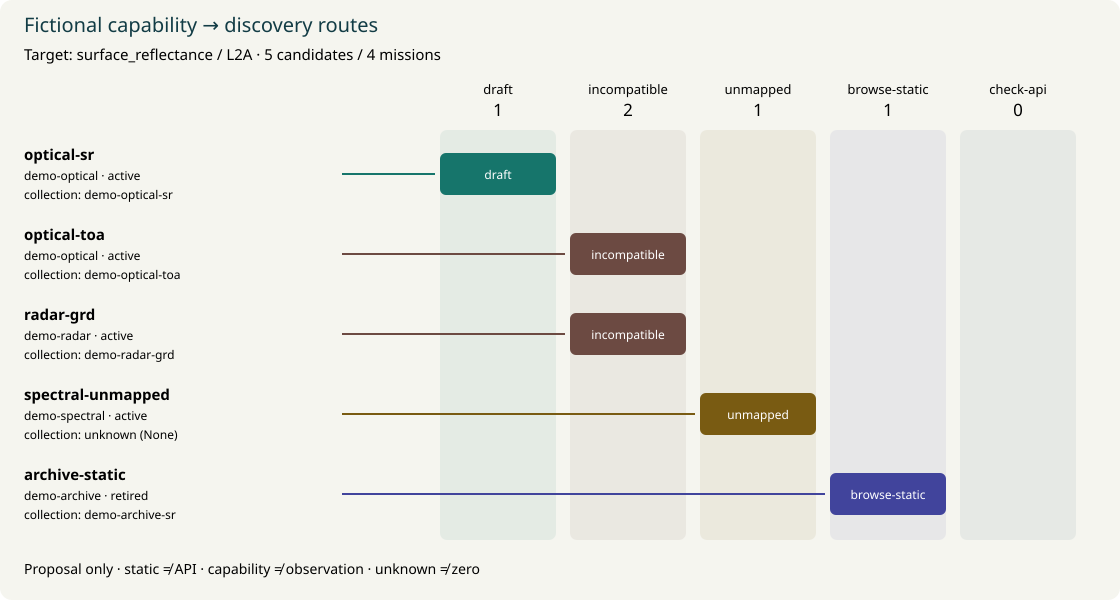

In [3]:
# All IDs below are fictional teaching metadata, not real provider collections.
candidates = [
    {'id': 'optical-sr', 'mission': 'demo-optical', 'status': 'active', 'collection': 'demo-optical-sr', 'property': 'surface_reflectance', 'processing': 'L2A', 'kind': 'api', 'item_search': True},
    {'id': 'optical-toa', 'mission': 'demo-optical', 'status': 'active', 'collection': 'demo-optical-toa', 'property': 'toa_reflectance', 'processing': 'L1C', 'kind': 'api', 'item_search': True},
    {'id': 'radar-grd', 'mission': 'demo-radar', 'status': 'active', 'collection': 'demo-radar-grd', 'property': 'backscatter', 'processing': 'GRD', 'kind': 'api', 'item_search': True},
    {'id': 'spectral-unmapped', 'mission': 'demo-spectral', 'status': 'active', 'collection': None, 'property': 'surface_reflectance', 'processing': 'L2A', 'kind': 'api', 'item_search': True},
    {'id': 'archive-static', 'mission': 'demo-archive', 'status': 'retired', 'collection': 'demo-archive-sr', 'property': 'surface_reflectance', 'processing': 'L2A', 'kind': 'static', 'item_search': False},
]
target_property = 'surface_reflectance'
target_processing = 'L2A'
bbox = [-10, -5, 10, 5]  # west, south, east, north in WGS84 degrees
start = '2024-06-01T00:00:00Z'
end = '2024-06-30T23:59:59Z'
limit = 3

routed, counts, proposals = discovery_plan(candidates, target_property, target_processing, bbox, start, end, limit)
candidate_count = len(candidates)
mission_count = len({r['mission'] for r in candidates})
print('Fictional candidates:', candidate_count, '| fictional missions:', mission_count)
print('Target:', target_property, '/', target_processing)
print('Routes:', counts)
for row in routed:
    collection = 'unknown (None)' if row['collection'] is None else row['collection']
    print(row['id'], '|', row['mission'], '|', row['status'], '| collection:', collection, '| property:', row['property'], '| processing:', row['processing'], '| route:', row['route'])
print('PRINTED PROPOSALS ONLY — no endpoint, method, file, network or model call:')
print(json.dumps(proposals, indent=2))

# Each named row moves to its current route lane. Labels and marks both follow edits.
colors = {'draft': '#16756b', 'incompatible': '#6c4a42', 'unmapped': '#795b12', 'browse-static': '#41449c', 'check-api': '#375a70'}
lane_x = {route: 440 + i * 130 for i, route in enumerate(ROUTES)}
body = '<text x="24" y="32" font-family="sans-serif" font-size="20" fill="#123c45">Fictional capability → discovery routes</text>'
body += f'<text x="24" y="60" font-family="sans-serif" font-size="15">Target: {escape(target_property)} / {escape(target_processing)} · {candidate_count} candidates / {mission_count} missions</text>'
for route in ROUTES:
    x = lane_x[route]
    body += f'<text x="{x+58}" y="94" text-anchor="middle" font-family="sans-serif" font-size="13">{route}</text><text x="{x+58}" y="116" text-anchor="middle" font-family="sans-serif" font-size="17">{counts[route]}</text>'
    body += f'<rect x="{x}" y="130" width="116" height="410" rx="7" fill="{colors[route]}" opacity="0.08"/>'
for i, row in enumerate(routed):
    y = 145 + i * 80
    collection = 'unknown (None)' if row['collection'] is None else row['collection']
    x = lane_x[row['route']]
    body += f'<g id="candidate-{escape(row["id"], quote=True)}" data-route="{row["route"]}"><text x="24" y="{y+15}" font-family="sans-serif" font-size="15" font-weight="bold">{escape(row["id"])}</text>'
    body += f'<text x="24" y="{y+35}" font-family="sans-serif" font-size="12">{escape(row["mission"])} · {escape(row["status"])}</text><text x="24" y="{y+54}" font-family="sans-serif" font-size="12">collection: {escape(collection)}</text>'
    body += f'<path d="M 342 {y+29} H {x-5}" stroke="{colors[row["route"]]}" stroke-width="2"/><rect class="route-mark" x="{x}" y="{y+8}" width="116" height="42" rx="6" fill="{colors[row["route"]]}"/><text x="{x+58}" y="{y+34}" text-anchor="middle" font-family="sans-serif" font-size="12" fill="white">{row["route"]}</text></g>'
body += '<text x="24" y="574" font-family="sans-serif" font-size="14">Proposal only · static ≠ API · capability ≠ observation · unknown ≠ zero</text>'
description = '; '.join(row['id'] + ': collection ' + ('unknown (None)' if row['collection'] is None else row['collection']) + ', route ' + row['route'] for row in routed)
svg(body, 'Fictional capability → discovery routes: ' + target_property + '/' + target_processing,
    description + '; route counts ' + str(counts) + '. All values and proposals are printed; no real missions or observations.', width=1120, height=600)


## Interpret the result

The default counts are **draft 1 / incompatible 2 / unmapped 1 / browse-static 1 / check-api 0**. Only `optical-sr` produces an envelope with `simulation: true`, `status: proposal-only`, collection `demo-optical-sr`, bbox `[-10, -5, 10, 5]`, the June 2024 UTC interval and `limit: 3`. These IDs are fictional and will not work against real services. The printed envelope supplies no endpoint or request method. No download or external publication occurs.

`spectral-unmapped` retains `unknown (None)` and cannot draft. The retired `archive-static` still takes the browse route because its product matches. Capability does not prove that a matching Item exists in the area/time, and an Item/Asset link does not prove suitability, rights or a successful pixel read. The diagram's lane, badge, counts, accessible description and printed table all follow the current calculation.

## Change one thing

1. Set `target_property = 'backscatter'` and `target_processing = 'GRD'`. Predict **one draft (`radar-grd`) and four incompatible**, then rerun the activity cell.
2. Restore surface reflectance/L2A. Set the first row's `item_search` to `False`: predict **zero drafts and one check-api**. Restore it afterward.
3. Set only the first row's `collection` to `None`: predict **two unmapped and zero drafts**. Check that unknown remains printed and drawn. Restore the mapping.
4. Try an invalid bbox such as `[10, -5, -10, 5]`, reversed dates, or `limit = 0`; run the cell and explain the `ValueError`. Restore the defaults and rerun before saving.

Record your prediction, observed routes and one piece of evidence needed to replace an invented mapping. Save a copy with **File → Save and Export Notebook As → Notebook** or the file browser's Download command. Browser storage is local to the browser/profile; it is not a GitHub commit, shared mapping database or EarthCODE record. This activity is bounded to five rows and normally completes within seconds; allow 60 seconds per cell during initial Python startup.


## EO Satellite Guide: six inspected source lessons

**Creators:** jltobias / James L. Tobias and EO Satellite Guide contributors. [Repository](https://github.com/jltobias/JupyterLite-EO-Satellite-Guide), [reviewed README](https://github.com/jltobias/JupyterLite-EO-Satellite-Guide/blob/2c607525ab06f52c77192889b2f01c5621714d0e/README.md), branch `main`, full commit `2c607525ab06f52c77192889b2f01c5621714d0e`, inspected 2026-11-02.

The source is a substantial interactive discovery course. Its poster has 13 representative platforms in five sensing families, with a verification snapshot of 2026-11-02. Its rings and slots are conceptual: they are not live satellite positions or an ephemeris. Search/filter by agency, sensing family, orbit, status, observed property and application; select a platform to unfold sensor/product evidence. Linked map/table highlights, pins retained across filters, contextual CSV, A1 print and a full-screen workspace support comparison rather than simply decorating a launch page.

Try a concrete walkthrough: filter a sensing family, pin two missions for comparison, expand sensor/product evidence, then record the observed property, processing level, qualified temporal detail and access route before searching STAC. The EO Guide's custom capability catalog is not already a STAC Catalog. Mission-family IDs may also differ from individual platform IDs in EarthCODE; preserve both levels and review the mapping.

| Immutable source notebook | What to investigate | Source Lab |
|---|---|---|
| [notebooks/01_constellation_poster.ipynb](https://github.com/jltobias/JupyterLite-EO-Satellite-Guide/blob/2c607525ab06f52c77192889b2f01c5621714d0e/notebooks/01_constellation_poster.ipynb) | Navigate the poster, unfold sensor/product evidence and compare capabilities | [Run source lesson](https://jltobias.github.io/JupyterLite-EO-Satellite-Guide/lab/index.html?path=01_constellation_poster.ipynb) |
| [notebooks/02_sensor_comparison.ipynb](https://github.com/jltobias/JupyterLite-EO-Satellite-Guide/blob/2c607525ab06f52c77192889b2f01c5621714d0e/notebooks/02_sensor_comparison.ipynb) | Query local metadata, preserve nulls and export contextual CSV | [Run source lesson](https://jltobias.github.io/JupyterLite-EO-Satellite-Guide/lab/index.html?path=02_sensor_comparison.ipynb) |
| [notebooks/03_hyperspectral_land.ipynb](https://github.com/jltobias/JupyterLite-EO-Satellite-Guide/blob/2c607525ab06f52c77192889b2f01c5621714d0e/notebooks/03_hyperspectral_land.ipynb) | Synthetic spectra and band averaging; radiance is not reflectance (source cites ARSET) | [Run source lesson](https://jltobias.github.io/JupyterLite-EO-Satellite-Guide/lab/index.html?path=03_hyperspectral_land.ipynb) |
| [notebooks/04_orbits_and_resolution.ipynb](https://github.com/jltobias/JupyterLite-EO-Satellite-Guide/blob/2c607525ab06f52c77192889b2f01c5621714d0e/notebooks/04_orbits_and_resolution.ipynb) | Generic circular orbits, period/repeat/cadence and native sampling versus resampled grids; not ephemerides | [Run source lesson](https://jltobias.github.io/JupyterLite-EO-Satellite-Guide/lab/index.html?path=04_orbits_and_resolution.ipynb) |
| [notebooks/05_observation_to_public_health.ipynb](https://github.com/jltobias/JupyterLite-EO-Satellite-Guide/blob/2c607525ab06f52c77192889b2f01c5621714d0e/notebooks/05_observation_to_public_health.ipynb) | An evidence/health worksheet and historical versus modern sensors; medical claims are not independently reviewed here | [Run source lesson](https://jltobias.github.io/JupyterLite-EO-Satellite-Guide/lab/index.html?path=05_observation_to_public_health.ipynb) |
| [notebooks/06_knowledge_graph_and_curation.ipynb](https://github.com/jltobias/JupyterLite-EO-Satellite-Guide/blob/2c607525ab06f52c77192889b2f01c5621714d0e/notebooks/06_knowledge_graph_and_curation.ipynb) | SOSA/DCAT/PROV profiles, evidence validation and graph export | [Run source lesson](https://jltobias.github.io/JupyterLite-EO-Satellite-Guide/lab/index.html?path=06_knowledge_graph_and_curation.ipynb) |

[Source poster](https://jltobias.github.io/JupyterLite-EO-Satellite-Guide/explorer/) · [source Book](https://jltobias.github.io/JupyterLite-EO-Satellite-Guide/book/intro.html) · [poster design](https://github.com/jltobias/JupyterLite-EO-Satellite-Guide/blob/2c607525ab06f52c77192889b2f01c5621714d0e/book/poster.md) · [data model](https://github.com/jltobias/JupyterLite-EO-Satellite-Guide/blob/2c607525ab06f52c77192889b2f01c5621714d0e/book/data-model.md) · [implementation](https://github.com/jltobias/JupyterLite-EO-Satellite-Guide/blob/2c607525ab06f52c77192889b2f01c5621714d0e/book/implementation.md) · [attributions](https://github.com/jltobias/JupyterLite-EO-Satellite-Guide/blob/2c607525ab06f52c77192889b2f01c5621714d0e/ATTRIBUTIONS.md).
The source catalog uses stable platform/sensor IDs, qualified spatial and temporal descriptors, explicit nulls, status/date and evidence groups. Its SOSA/DCAT/PROV JSON-LD is a generated view: capability metadata is not an actual observation, and no validated cross-ontology equivalence is established. The standalone poster HTML can work offline; fresh source JupyterLite startup still downloads Pyodide. Its local catalog and eo_guide.py helper belong to the source, not this atlas activity.
Eight exact EO entry URLs and two ESA entries returned HTTP 200 on 2026-11-02. [Dated launch evidence](https://jltobias.github.io/JupyterLite-Learning-Atlas/catalog/launch-checks.json) retains resolved URLs and a separate normalized [published manifest](https://jltobias.github.io/JupyterLite-EO-Satellite-Guide/api/contents/all.json) observation with source pin, SHA-256 and all six notebook basenames. Reachability and filename presence certify neither source execution nor widgets, providers or EarthCODE functions.
The EO Satellite Guide is by **jltobias / James L. Tobias and EO Satellite Guide contributors**. Its [root MIT license](https://github.com/jltobias/JupyterLite-EO-Satellite-Guide/blob/2c607525ab06f52c77192889b2f01c5621714d0e/LICENSE) covers its original work; third-party materials keep separate terms. The source poster uses Natural Earth 1:110m public-domain land geometry: credit **Tom Patterson, Nathaniel Vaughn Kelso and Natural Earth contributors**, [terms](https://www.naturalearthdata.com/about/terms-of-use/). No source geography, screenshot, mission records, code, prose or imagery is copied here. The source-supplied raster has unestablished original rights and is excluded. This atlas's original executable code is MIT; narrative, fictional fixtures and generated SVG are CC BY 4.0, **James L. Tobias and JupyterLite Learning Atlas contributors (2026)**. Linked standards, ESA resources and source courses retain their creators' terms; no endorsement is implied.


## A proposed poster → STAC → EarthCODE connection

**Design proposal, not a deployed connector or an upstream merge.** Begin with the poster's human question: which capability might measure an observed property at a defensible scale and time? A platform can carry several sensors; sensors and processing levels can produce several products; products can map to several provider collections, and collections can contain products from several platforms. Curate these many-to-many relationships using stable IDs, product definitions, levels, evidence URLs, review date and mapping version. Do not join mission names to collection names by string equality. Keep `None` explicit until someone verifies a mapping.

| Stage | Proposed contract and deliberate user action | Evidence or stopping condition |
|---|---|---|
| 1. Capability discovery | Poster filters, selected platform/sensor/property and a question | Preserve evidence, nulls, status/date and native sampling; capability is not an acquisition |
| 2. Curated mapping | A versioned table: platform/sensor IDs → product/property/processing level → provider collection ID, reviewer and source | Ambiguous or missing mapping stays unmapped; a retired mission can still have an archive |
| 3. Bounded metadata search | User confirms a small WGS84 area, dates, collection and page limit | Inspect provider landing links and conformance. A static Catalog/Collection takes the browse route; only advertised API Item Search supports a search draft |
| 4. Asset review | Inspect returned Items and each Asset's metadata, license, dates, units and suitability | Metadata/footprints do not establish pixel quality. CORS, authentication/signing, memory and rights can block a later download |
| 5. Appropriate workflow | Choose a bounded local or cloud tool with declared input/output and environment | Record code/version, environment, parameters, input IDs/licenses, output checks and limitations; do not assume Pyodide can execute native/GPU workflows |
| 6. Possible EarthCODE sharing | After validation, prepare a workflow/experiment record and results for the relevant publication process | Record provenance and meet provider/programme review, account, resource and eligibility requirements before publication or execution |

STAC Catalogs organize links, Collections describe sets, Items describe spatiotemporal resources and Assets link files. Item metadata is distinct from an actual measurement or pixel read. The STAC Browser source already connects to WorldPop, Copernicus, Earth Search and Planetary Computer, browses static catalogs, supports bounded bbox/polygon/date metadata search and exports completed searches/items. It examines asset rights and offers explicit optional download/crop/downstream actions. Protected CDSE session controls are optional; anonymous access is not universal. Its present handoffs target other tools. No EO importer, receiving URL-query contract, arbitrary `/search` endpoint or POST support is assumed here. A future adapter needs an agreed schema, validation, user preview and explicit receiver implementation; use advertised API links and supported methods.

The printed envelope below proposes only intent and STAC search fields. Neither STAC Browser nor EarthCODE currently imports this teaching profile. A future pilot must replace fictional IDs with human-reviewed real provider mappings and keep the confirmation boundary visible. AI could suggest mappings with citations, but an accountable person must approve and version them.

EarthCODE is ESA's open-science ecosystem for discovering and sharing methods/results, its Open Science Catalog, platforms and resources. Its catalog interlinks missions, variables, projects, products, workflows and experiments. Static project/product metadata is STAC-based; workflow records use **OGC API Records**. Heterogeneous JSON is not automatically a STAC raster Item. A catalog link or notebook alone does not demonstrate reproduction: code, environment, input/output evidence and workflow/experiment provenance matter. Execution may require platform accounts/resources; Network of Resources sponsorship/eligibility and publication review depend on programme/provider. No cloud execution, account creation, publication or submission happens here, and EarthCODE workflows are not all free, offline or Pyodide-compatible.

For a small human-centered pilot, ask learners to move from a question to one defensible dataset while preserving an uncertainty or blocked state. Measure task completion, time to first defensible dataset, mistaken capability-to-observation inferences, and whether keyboard/screen-reader users can inspect evidence and recover from an unmapped/static/API state. Collect accessibility feedback and revise the mapping/preview before extending scope. These are proposed evaluation measures; no usability outcomes are claimed.


## Consulted standards and EarthCODE resources

- **STAC community.** [STAC specification overview](https://stacspec.org/en/about/stac-spec/): Catalog, Collection, Item and Asset roles. [STAC API Item Search v1.0.0](https://github.com/radiantearth/stac-api-spec/blob/v1.0.0/item-search/README.md): advertised links/conformance, required GET and optional POST support, collections/bbox/datetime/limit; bbox and intersects are mutually exclusive. Static catalogs do not imply Item Search.
- **W3C/OGC.** [SSN/SOSA](https://www.w3.org/TR/vocab-ssn/) describes sensors, observations and observed properties. **W3C.** [DCAT 3](https://www.w3.org/TR/vocab-dcat-3/), Recommendation 2024-08-22, describes cataloged resources; [PROV-O](https://www.w3.org/TR/prov-o/), Recommendation 2013-04-30, describes entities, activities, agents and derivation. These roles inform the proposal; the atlas asserts no `sameAs` mappings and implements no reasoning engine.
- **ESA EarthCODE and contributors.** [Portal](https://earthcode.esa.int/) and [About](https://earthcode.esa.int/about), inspected 2026-11-02; [Open Science Catalog](https://opensciencedata.esa.int/products/catalog), [catalog overview](https://esa-earthcode.github.io/documentation/Technical%20Documentation/Open%20Science%20Catalog/Open%20Science%20Catalog%20Overview), [discovery guide](https://esa-earthcode.github.io/documentation/Technical%20Documentation/Open%20Science%20Catalog/Discovering%20Resources), [workflows and experiments](https://esa-earthcode.github.io/documentation/Technical%20Documentation/Workflows%20and%20Experiments/working-with-workflows), and [FAQ](https://esa-earthcode.github.io/documentation/Getting%20started%20with%20EarthCODE/Frequently%20Asked%20Questions). These are ecosystem/documentation references, not connected services or a promise of free/offline execution.
- **jltobias / James L. Tobias and STAC Browser contributors.** [STAC Browser README](https://github.com/jltobias/JupyterLite-STAC-Browser/blob/945d8b31c59e2cf93f9e51e855eb062fb1b4321c/README.md), full commit `945d8b31c59e2cf93f9e51e855eb062fb1b4321c`, MIT; integration-context inspection 2026-11-02. Its [app.js](https://github.com/jltobias/JupyterLite-STAC-Browser/blob/945d8b31c59e2cf93f9e51e855eb062fb1b4321c/web/app.js) has no EO-specific importer or URL-query handoff contract. The atlas's existing STAC source record remains dated 2026-11-01.

Only used source material is adopted as consulted here. Scientific readings that occur only in the source course remain its references, not independently inspected atlas evidence.


## Sources, continuation and limits

**Source README:** [reviewed immutable version](https://github.com/jltobias/JupyterLite-EO-Satellite-Guide/blob/2c607525ab06f52c77192889b2f01c5621714d0e/README.md), inspected 2026-11-02. Keep source runtime, data and third-party rights separate from this original atlas exercise. The actual six source lessons, consulted primary standards and ESA resources are credited above and in the [central references](../../references.ipynb).

Continue first by reading the source poster and comparing its evidence fields with the [STAC chapter](../stac-browser/index.ipynb). For a future integration, agree the mapping schema and receiver behavior, review one real collection's property/level and advertised API capability, then let a learner preview one bounded proposal. Review asset permissions and resource needs before deliberate local/cloud execution. Source entry checks do not validate source scientific claims, all notebook behavior or provider services. No integration is deployed or published here.

[Choose another learning path](../../index.ipynb) · [Contribute](../../contributor-guide.ipynb)
